In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path
from sklearn.multioutput import MultiOutputRegressor
from lightgbm import LGBMRegressor
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [77]:
dir = Path.cwd().parent / "data"
df_train = pd.read_parquet(dir/"train.parquet")
df_val = pd.read_parquet(dir/"test.parquet")

In [79]:
# 1. Variables a eliminar (Textos, Metadatos, Deterministas y Descartadas)
p_columnas = [f'p{i}' for i in range(1, 13)]

cols_drop = [
    # Textos y Metadatos
    'BEAM', 'COLUMN', 'DrawingCode', 'AceroEstructural', 'EstandarTornillos',
    'Source', 'standard', 'BEAM_type', 'COLUMN_type',
    # Deterministas
    'Hole', 'Lp', 
] + p_columnas

# 3. Definir características (X) y separar Targets
targets_tornillos = ['Bolt', 'g', 'e', 'd'] + [f'p{i}_acum' for i in range(1, 13)]
targets_placa = ['tp', 'Bp', 'tws', 'ts', 'tbs', 'tst']

In [80]:
def generar_distancias_acumuladas(df, p_cols, origen_col=None):
    """
    Transforma distancias relativas entre tornillos a distancias acumuladas desde el borde/origen.
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame que contiene las columnas de distancias relativas.
    p_cols : list
        Lista ordenada con los nombres de las columnas ['p1', 'p2', ..., 'p12'].
    origen_col : str, opcional
        Nombre de la columna del borde inicial (ej. 'e'), si deseas empezar el 
        acumulado desde el primer borde de la placa. Si es None, arranca en p1.
        
    Returns:
    --------
    pd.DataFrame con las columnas acumuladas.
    """
    df_acum = df.copy()
    
    # 1. Seleccionar la matriz de distancias relativas
    matriz_relativa = df[p_cols].values
    
    # 2. Si hay un borde de origen (ej. 'e'), sumarlo como punto de partida X0
    if origen_col and origen_col in df.columns:
        origen = df[origen_col].values[:, np.newaxis]
        # Sumar acumulativamente a lo largo del eje de columnas (axis=1)
        matriz_acumulada = origen + np.cumsum(matriz_relativa, axis=1)
    else:
        matriz_acumulada = np.cumsum(matriz_relativa, axis=1)
        
    # 3. Asignar los nuevos nombres de columnas acumuladas
    acum_cols = [f'{col}_acum' for col in p_cols]
    
    # 4. Reemplazar o añadir las nuevas columnas al DataFrame
    df_acum[acum_cols] = matriz_acumulada
    
    return df_acum


df_train = generar_distancias_acumuladas(df_train, p_cols=p_columnas, origen_col='e')
df_val = generar_distancias_acumuladas(df_val, p_cols=p_columnas, origen_col='e')

In [81]:
X_train = df_train.drop(columns=cols_drop + targets_tornillos + targets_placa)
X_val = df_val.drop(columns=cols_drop + targets_tornillos + targets_placa)

## Predecir variables de tornillos

In [71]:
Y1_train = df_train[targets_tornillos]
Y1_val = df_val[targets_tornillos]

In [25]:
modelo_tornillos = MultiOutputRegressor(
    LGBMRegressor(
        n_estimators=200, 
        max_depth=6, 
        learning_rate=0.05, 
        random_state=42,
        n_jobs=-1,
    )
)
modelo_tornillos.fit(X_train, Y1_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001351 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1048
[LightGBM] [Info] Number of data points in the train set: 3777, number of used features: 23
[LightGBM] [Info] Start training from score 24.572677
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.,LGBMRegressor...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[<U15](23,)","['Capacity_Moment','Capacity_Shear','Capacity_Axial',...,'fy_tornillo_mpa', 'fu_tornillo_mpa','fv_tornillo_mpa']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,23
,max_depth,6
,learning_rate,0.05
,n_estimators,200
,random_state,42
,n_jobs,-1


In [48]:
Y1_pred = modelo_tornillos.predict(X_val)

In [50]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluar_multioutput(Y_real, Y_pred, targets_names):
    # Desvincular índices de Pandas convirtiendo a arrays de NumPy (.values)
    Y_real_np = Y_real.values if isinstance(Y_real, (pd.DataFrame, pd.Series)) else Y_real
    Y_pred_np = Y_pred.values if isinstance(Y_pred, (pd.DataFrame, pd.Series)) else Y_pred
    
    resultados = []
    
    for i, col in enumerate(targets_names):
        y_true = Y_real_np[:, i]
        y_p = Y_pred_np[:, i]
        
        mae = mean_absolute_error(y_true, y_p)
        rmse = np.sqrt(mean_squared_error(y_true, y_p))
        r2 = r2_score(y_true, y_p)
        
        # Diferencia posicional exacta
        error_abs = np.abs(y_true - y_p)
        pct_dentro_2mm = (error_abs <= 2.0).mean() * 100
        pct_dentro_5mm = (error_abs <= 5.0).mean() * 100
        
        resultados.append({
            'Variable': col,
            'MAE (mm)': round(mae, 2),
            'RMSE (mm)': round(rmse, 2),
            'R2 Score': round(r2, 3),
            '% Error <= 2mm': round(pct_dentro_2mm, 1),
            '% Error <= 5mm': round(pct_dentro_5mm, 1)
        })
    
    df_res = pd.DataFrame(resultados)
    print("=== EVALUACIÓN CORREGIDA POR VARIABLE ===")
    print(df_res.to_string(index=False))
    return df_res

# Ejecutar con tus variables:
# df_reporte = evaluar_multioutput_corregido(Y1_val, Y1_pred, targets_tornillos)

# Ejemplo de uso con las predicciones del Modelo 1:
evaluar_multioutput(Y1_val, Y1_pred, targets_tornillos)

=== EVALUACIÓN CORREGIDA POR VARIABLE ===
Variable  MAE (mm)  RMSE (mm)  R2 Score  % Error <= 2mm  % Error <= 5mm
    Bolt      0.61       1.12     0.928            92.9            99.0
       g      2.74       4.94     0.897            60.1            85.1
       e      0.97       1.88     0.896            86.7            96.7
       d      1.29       2.27     0.927            80.6            94.3
      p1      2.88       5.37     0.949            61.8            85.7
      p2      7.87      14.95     0.835            33.4            59.3
      p3      8.28      13.72     0.912            26.6            54.3
      p4     11.58      18.27     0.927            18.5            39.7
      p5     12.00      20.05     0.904            28.3            45.2
      p6     10.38      20.45     0.898            42.8            58.8
      p7      3.63      11.82     0.933            74.5            84.7
      p8      1.02       5.89     0.967            91.3            95.7
      p9      0.35    

,Variable,MAE (mm),RMSE (mm),R2 Score,% Error <= 2mm,% Error <= 5mm
0,Bolt,0.61,1.12,0.928,92.9,99.0
1,g,2.74,4.94,0.897,60.1,85.1
2,e,0.97,1.88,0.896,86.7,96.7
3,d,1.29,2.27,0.927,80.6,94.3
4,p1,2.88,5.37,0.949,61.8,85.7
5,p2,7.87,14.95,0.835,33.4,59.3
6,p3,8.28,13.72,0.912,26.6,54.3
7,p4,11.58,18.27,0.927,18.5,39.7
8,p5,12.00,20.05,0.904,28.3,45.2
9,p6,10.38,20.45,0.898,42.8,58.8


In [39]:
def evaluar_clasificacion_comercial(y_true_bolt, y_pred_bolt):
    """
    Evalúa la precisión de la predicción del diámetro de tornillo 
    tras ajustarlo al diámetro métrico estándar más cercano (M16, M20, M24, M27, M30).
    """
    medidas_comerciales = np.array([16, 20, 24, 27, 30, 36])
    
    # Ajustar cada predicción continua al diámetro comercial superior o más cercano
    y_pred_comercial = [
        medidas_comerciales[np.argmin(np.abs(medidas_comerciales - val))] 
        for val in y_pred_bolt
    ]
    
    precisión_exacta = (y_true_bolt == y_pred_comercial).mean() * 100
    print(f"Precisión exacta del tornillo comerciado (Bolt): {precisión_exacta:.2f}%")

evaluar_clasificacion_comercial(Y1_val["Bolt"], Y1_pred[:,0])

Precisión exacta del tornillo comerciado (Bolt): 90.05%


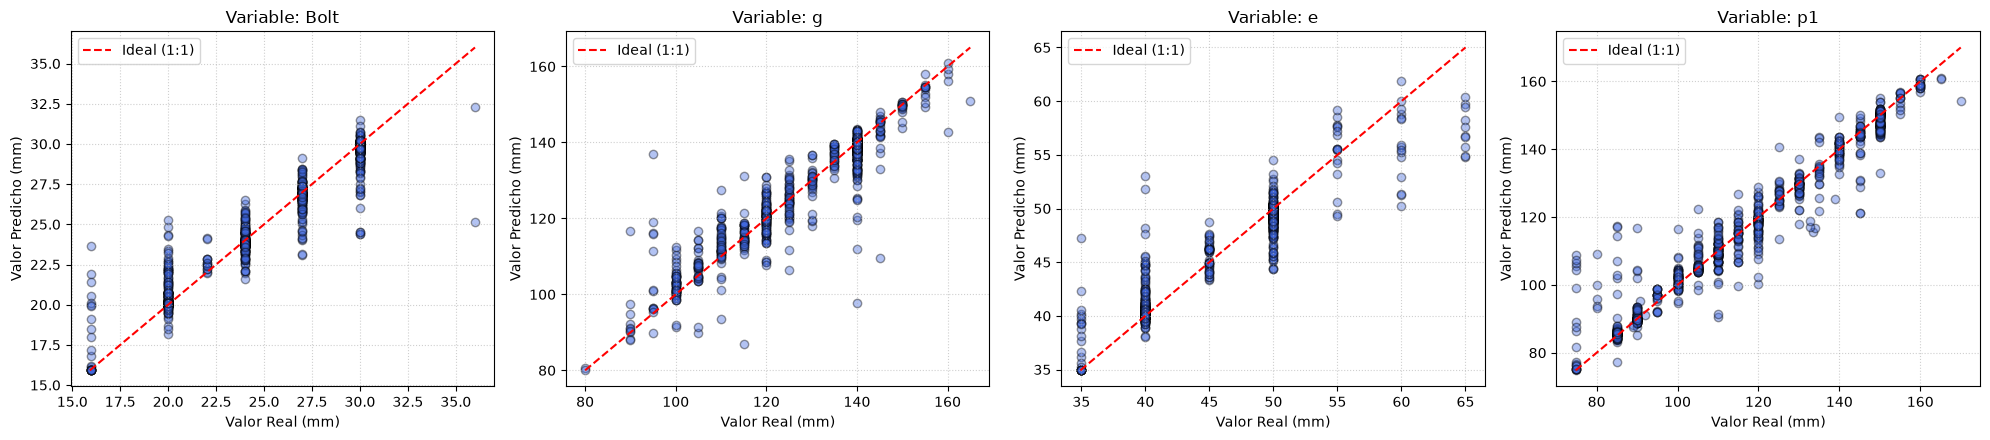

In [ ]:
def graficar_evaluacion_multioutput(Y_real, Y_pred, variables_clave):
    """
    Genera gráficos de dispersión (Real vs Predicho) para las variables seleccionadas.
    """
    num_vars = len(variables_clave)
    fig, axes = plt.subplots(1, num_vars, figsize=(5 * num_vars, 4.5))
    if num_vars == 1:
        axes = [axes]
        
    for ax, var in zip(axes, variables_clave):
        y_t = Y_real[var]
        y_p = Y_pred[var]
        
        # Gráfico de dispersión
        ax.scatter(y_t, y_p, alpha=0.4, edgecolors='k', color='royalblue')
        
        # Línea de predicción perfecta (y = x)
        lims = [min(y_t.min(), y_p.min()), max(y_t.max(), y_p.max())]
        ax.plot(lims, lims, 'r--', label='Ideal (1:1)')
        
        ax.set_title(f'Variable: {var}')
        ax.set_xlabel('Valor Real (mm)')
        ax.set_ylabel('Valor Predicho (mm)')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)
        
    plt.tight_layout()
    plt.show()

# Ejemplo de uso para las variables clave:
graficar_evaluacion_multioutput(Y1_val, pd.DataFrame(Y1_pred, columns=Y1_val.columns), ['Bolt', 'g', 'e', 'p1'])

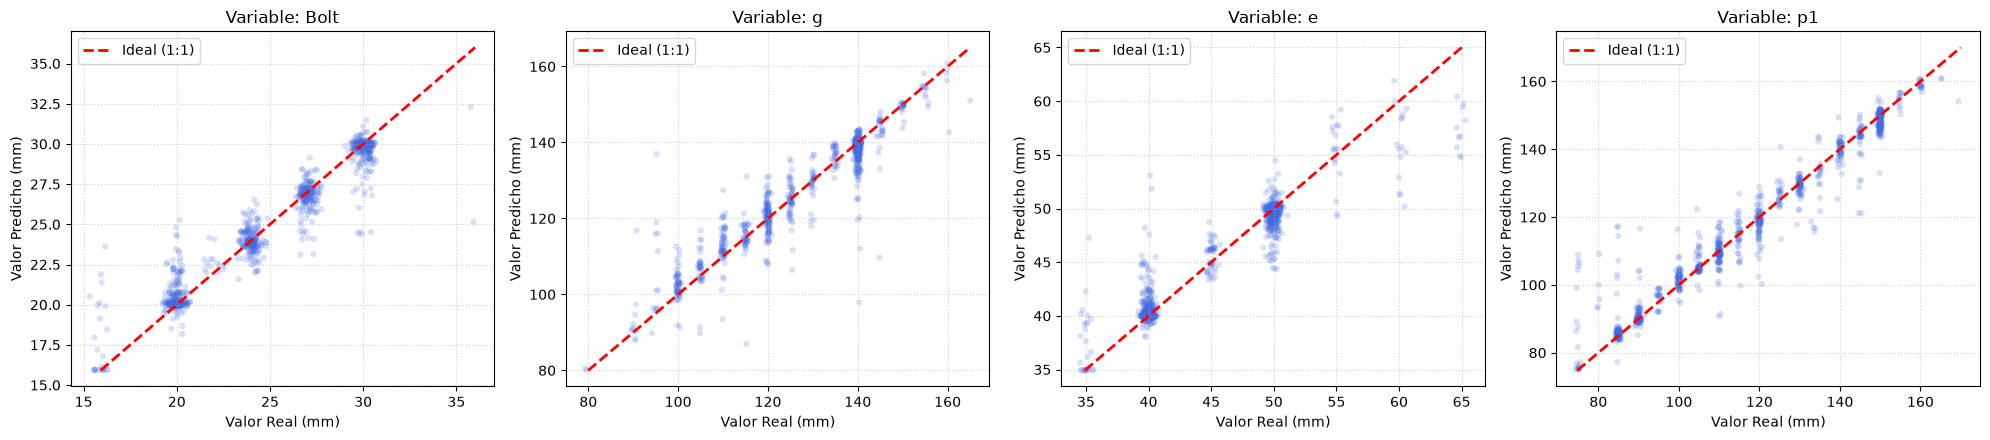

In [44]:
import numpy as np
import matplotlib.pyplot as plt

def graficar_evaluacion_multioutput_jitter(Y_real, Y_pred, variables_clave, jitter_factor=0.3):
    num_vars = len(variables_clave)
    fig, axes = plt.subplots(1, num_vars, figsize=(5 * num_vars, 4.5))
    if num_vars == 1:
        axes = [axes]
        
    for ax, var in zip(axes, variables_clave):
        y_t = Y_real[var].values
        y_p = Y_pred[var].values
        
        # Añadir un pequeño ruido en X solo para despegar los puntos en la gráfica
        x_jitter = y_t + np.random.normal(0, jitter_factor, size=len(y_t))
        
        # Gráfico de dispersión con alfa bajo para ver densidad
        ax.scatter(x_jitter, y_p, alpha=0.2, edgecolors='none', color='royalblue', s=20)
        
        # Línea de predicción perfecta
        lims = [min(y_t.min(), y_p.min()), max(y_t.max(), y_p.max())]
        ax.plot(lims, lims, 'r--', label='Ideal (1:1)', linewidth=2)
        
        ax.set_title(f'Variable: {var}')
        ax.set_xlabel('Valor Real (mm)')
        ax.set_ylabel('Valor Predicho (mm)')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)
        
    plt.tight_layout()
    plt.show()

# Uso:
graficar_evaluacion_multioutput_jitter(Y1_val, pd.DataFrame(Y1_pred, columns=Y1_val.columns), ['Bolt', 'g', 'e', 'p1'])

# Predecir grosor de placa/rigidizadores

In [54]:
Y2_train = df_train[targets_placa]
Y2_val = df_val[targets_placa]

In [55]:
modelo_placa = MultiOutputRegressor(
    LGBMRegressor(
        n_estimators=200, 
        max_depth=6, 
        learning_rate=0.05, 
        random_state=42,
        n_jobs=-1,
    )
)
modelo_placa.fit(X_train, Y2_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000614 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1048
[LightGBM] [Info] Number of data points in the train set: 3777, number of used features: 23
[LightGBM] [Info] Start training from score 22.276145
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.,LGBMRegressor...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), LGBMRegressor...ndom_state=42), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[<U15](23,)","['Capacity_Moment','Capacity_Shear','Capacity_Axial',...,'fy_tornillo_mpa', 'fu_tornillo_mpa','fv_tornillo_mpa']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,23
,max_depth,6
,learning_rate,0.05
,n_estimators,200
,random_state,42
,n_jobs,-1


In [57]:
Y2_pred = modelo_placa.predict(X_val)

In [62]:
evaluar_multioutput(Y2_val, Y2_pred, targets_placa)

=== EVALUACIÓN CORREGIDA POR VARIABLE ===
Variable  MAE (mm)  RMSE (mm)  R2 Score  % Error <= 2mm  % Error <= 5mm
      tp      1.17       2.00     0.873            83.0            96.1
      Bp      2.91       6.20     0.986            66.3            80.5
     tws      0.45       1.65     0.392            94.5            97.6
      ts      0.76       1.78     0.838            89.2            96.8
     tbs      1.07       1.80     0.936            83.8            96.6
     tst      0.39       1.56     0.929            95.4            97.7


,Variable,MAE (mm),RMSE (mm),R2 Score,% Error <= 2mm,% Error <= 5mm
0,tp,1.17,2.00,0.873,83.0,96.1
1,Bp,2.91,6.20,0.986,66.3,80.5
2,tws,0.45,1.65,0.392,94.5,97.6
3,ts,0.76,1.78,0.838,89.2,96.8
4,tbs,1.07,1.80,0.936,83.8,96.6
5,tst,0.39,1.56,0.929,95.4,97.7


In [73]:
Y1_val

,Bolt,g,e,d,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12
0,24,140,50,50.0,105.0,80.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,20,110,40,37.0,85.0,75.0,85.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,24,120,40,50.0,110.0,70.0,85.0,130.0,70.0,135.0,0.0,0.0,0.0,0.0,0.0,0.0
3,27,115,60,45.0,75.0,75.0,215.0,240.0,75.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24,110,50,50.0,120.0,140.0,140.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
940,20,105,40,39.0,89.0,60.0,85.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
941,20,140,40,40.0,85.0,60.0,85.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
942,16,95,35,35.0,75.0,45.0,140.0,155.0,45.0,95.0,0.0,0.0,0.0,0.0,0.0,0.0
943,30,145,50,60.0,135.0,85.0,175.0,175.0,130.0,230.0,85.0,165.0,0.0,0.0,0.0,0.0


In [74]:
Y1_val[["p1", "p2", "p3", "p4", "p5"]]

,p1,p2,p3,p4,p5
0,105.0,80.0,105.0,0.0,0.0
1,85.0,75.0,85.0,0.0,0.0
2,110.0,70.0,85.0,130.0,70.0
3,75.0,75.0,215.0,240.0,75.0
4,120.0,140.0,140.0,120.0,0.0
...,...,...,...,...,...
940,89.0,60.0,85.0,0.0,0.0
941,85.0,60.0,85.0,0.0,0.0
942,75.0,45.0,140.0,155.0,45.0
943,135.0,85.0,175.0,175.0,130.0
